<a href="https://colab.research.google.com/github/wachirapatsiri/personal-finance-pipeline-dashboard/blob/main/Personal_Finance_Data_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💰 Personal Finance Data Pipeline & Dashboard

## 📌 Project Overview
An end-to-end data pipeline built to automate the extraction, cleaning, and categorization of personal finance transactions, culminating in an interactive dashboard for financial tracking.

## 🎯 Business Problem
Tracking personal expenses manually is time-consuming. Transaction records often contain messy data, inconsistent date formats, and spelling variations for the same merchant (e.g., "Shopee", "SHOPEE THAILAND"), making it difficult to analyze spending behaviors accurately.

## 🛠️ Solution & Action (Tech Stack: Python, Pandas, Matplotlib)
* **Data Cleaning:** Processed raw financial data by handling missing values, normalizing text, and standardizing datetime formats.
* **Fuzzy Matching:** Implemented string matching algorithms to automatically detect and categorize similar merchant names, reducing manual tagging errors.
* **Data Visualization:** Developed a comprehensive dashboard to visualize monthly cash flows, expense breakdowns by category, and top 10 frequent merchants.

## 📈 Key Results
* Successfully automated the data preparation process, saving hours of manual data entry.
* Provided clear visibility into spending habits, enabling better budget optimization and financial planning.

## 1. Setup & Import Libraries
เริ่มต้นด้วยการนำเข้าไลบรารีที่จำเป็นสำหรับการจัดการข้อมูล (Pandas, NumPy) การทำ Text Analysis (Thefuzz) และการสร้าง Data Visualization (Matplotlib, Seaborn) รวมถึงการตั้งค่าฟอนต์ภาษาไทย

In [ ]:
# ดาวน์โหลดฟอนต์ภาษาไทย TH Sarabun New
!wget -q https://github.com/Phonbopit/sarabun-webfont/raw/master/fonts/thsarabunnew-webfont.ttf

In [ ]:
!pip install thefuzz

In [ ]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from datetime import datetime
from thefuzz import process, fuzz

In [ ]:
# ติดตั้งและตั้งค่าให้ Matplotlib ใช้ฟอนต์ภาษาไทย
mpl.font_manager.fontManager.addfont('thsarabunnew-webfont.ttf')
mpl.rc('font', family='TH Sarabun New', size=14)

## 📥 1. Data Extraction & Basic Exploration
โหลดข้อมูลธุรกรรมจำลองจากไฟล์ CSV และตรวจสอบโครงสร้างข้อมูลเบื้องต้นเพื่อประเมินคุณภาพของข้อมูล (Data Quality)

In [ ]:
df = pd.read_csv('/content/mock_bank_statement.csv')


In [ ]:
print("ข้อมูล 10 บรรทัดแรก")
df.head(10)

ข้อมูล 10 บรรทัดแรก


,transaction_id,date,description,type,amount,balance,note
0,TXN02049,06-12-2026,Grabb,รายจ่าย,82.06,139781.63,NaN
1,TXN00826,25-02-2026,ร้านลุงมี ก๋วยเตี๋ยวเรือ,รายจ่าย,888.73,25311.63,NaN
2,TXN01540,13/07/2026,7-elevn,รายจ่าย,261.97,9474.74,NaN
3,TXN02054,2026-04-05,Seven Eleven,รายจ่าย,232.74,-11433.43,NaN
4,TXN00338,2026-01-08,Grab,รายจ่าย,866.63,21604.58,NaN
5,TXN02670,10-10-2026,รายได้ฟรีแลนซ์,รายรับ,777.98,99964.07,NaN
6,TXN01241,18-07-2026,ดอกเบี้ยเงินฝาก,รายรับ,52.37,14509.34,NaN
7,TXN02299,26/03/2026,lotus,รายจ่าย,546.22,8545.18,NaN
8,TXN02927,2026-12-04,Shopee Thailand,รายจ่าย,96.10,131644.43,NaN
9,TXN01571,17-03-2026,การไฟฟ้าส่วนภูมิภาค,รายจ่าย,580.48,9613.91,NaN


In [ ]:
null_counts = df.isna().sum()
print(null_counts)

transaction_id       0
date                 0
description          0
type                 0
amount             170
balance              0
note              3090
dtype: int64


In [ ]:
duplicate_count = df.duplicated().sum()
print(duplicate_count)

90


In [ ]:
df['description'].unique()

array(['Grabb', 'ร้านลุงมี ก๋วยเตี๋ยวเรือ', '7-elevn', 'Seven Eleven',
       'Grab', 'รายได้ฟรีแลนซ์', 'ดอกเบี้ยเงินฝาก', 'lotus',
       'Shopee Thailand', 'การไฟฟ้าส่วนภูมิภาค', 'โอนเงินจาก เพื่อน',
       '  TRUE  ', 'starbucks coffee', 'Boots Thailand', 'เงินคืนภาษี',
       '  LOTUS  ', '7-ELEVEN', 'shopee', '  การไฟฟ้าส่วนภูมิภาค  ',
       'โอนเงินจาก แม่', 'GRAB RIDE', 'True Corporation', '  GRABB  ',
       "Lotus's", '  TRUE CORPORATION  ', 'Netflix.com', 'Starbucks',
       'ค่าคอมมิชชั่น', '  ร้านลุงมี ก๋วยเตี๋ยวเรือ  ', 'TRUE',
       'เงินเดือน/ค่าขนมรายเดือน', '  NETFLIX.COM  ', 'Lotuss',
       'cashback shopee', '  7-ELEVEN  ', '  STARBUCKS  ', '  LOTUSS  ',
       '  SEVEN ELEVEN  ', '  GRAB  ', '  STARBUCKS COFFEE  ',
       "  LOTUS'S  ", '  SHOPEE  ', '  SHOPEE THAILAND  ', '  7-ELEVN  ',
       '  GRAB RIDE  ', '  BOOTS THAILAND  '], dtype=object)

In [ ]:
print("ภาพรวมของข้อมูล (Data Info)")
df.info()

ภาพรวมของข้อมูล (Data Info)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3090 entries, 0 to 3089
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  3090 non-null   object 
 1   date            3090 non-null   object 
 2   description     3090 non-null   object 
 3   type            3090 non-null   object 
 4   amount          2920 non-null   float64
 5   balance         3090 non-null   float64
 6   note            0 non-null      float64
dtypes: float64(3), object(4)
memory usage: 169.1+ KB


In [ ]:
df.describe()

,amount,balance,note
count,2920.000000,3090.000000,0.0
mean,776.073644,48378.437825,NaN
std,1688.590757,57958.220753,NaN
min,6.500000,-39891.630000,NaN
25%,224.642500,362.102500,NaN
50%,492.280000,26363.775000,NaN
75%,744.610000,109098.060000,NaN
max,14701.050000,150555.100000,NaN


## 🧹 2. Data Cleaning & Preprocessing
กระบวนการทำความสะอาดข้อมูล แบ่งออกเป็น 4 ขั้นตอนหลัก เพื่อให้ได้ข้อมูลที่พร้อมสำหรับการวิเคราะห์

In [ ]:
df_raw = df.copy()
total_raw = len(df)   # เก็บจำนวนแถวดิบไว้ตั้งแต่ก่อน cleaning เพื่อดูก่อน-หลัง

**Text Normalization (ปรับมาตรฐานข้อความ)**

ลบช่องว่างส่วนเกินหน้า-หลังและแปลงตัวอักษรเป็นพิมพ์เล็กทั้งหมดเพื่อลดความซ้ำซ้อนของข้อมูล

In [ ]:
# จัดการรายการ description
# ลบช่องว่างส่วนเกินหน้า-หลัง และแปลงเป็นตัวพิมพ์เล็กทั้งหมด เพื่อให้ง่ายต่อการเทียบคำ
df['description_cleaned'] = df['description'].astype(str).str.strip().str.lower()

df[['description', 'description_cleaned']].head()

,description,description_cleaned
0,Grabb,grabb
1,ร้านลุงมี ก๋วยเตี๋ยวเรือ,ร้านลุงมี ก๋วยเตี๋ยวเรือ
2,7-elevn,7-elevn
3,Seven Eleven,seven eleven
4,Grab,grab


In [ ]:
#จัดการค่าว่างในคอลัมน์ที่จำเป็น
required_cols = ['transaction_id', 'date', 'description', 'amount']
null_mask = df[required_cols].isna().any(axis=1)
null_required = int(null_mask.sum())
df = df[~null_mask]
print(f"ค่าว่างในคอลัมน์จำเป็น: {null_required} แถว (ตัดออก)")

ค่าว่างในคอลัมน์จำเป็น: 170 แถว (ตัดออก)


In [ ]:
print(df_raw.isna().sum())

transaction_id       0
date                 0
description          0
type                 0
amount             170
balance              0
note              3090
dtype: int64


In [ ]:
print(df.isna().sum())

transaction_id            0
date                      0
description               0
type                      0
amount                    0
balance                   0
note                   2920
description_cleaned       0
dtype: int64


**Handling Missing & Messy Amounts (จัดการยอดเงิน)**

ลบสัญลักษณ์ที่ไม่เกี่ยวข้องออก และแปลงชนิดข้อมูลให้อยู่ในรูปแบบตัวเลข (Float)

In [ ]:
# จัดการรูปแบบในจำนวนเงิน (Handling Missing & Messy Amounts)
# ตัด comma และสัญลักษณ์เงิน (เช่น "1,250.00", "฿1250") ออกก่อนแปลงเป็นตัวเลข
# ค่าที่แปลงไม่ได้จะกลายเป็น NaN แล้วถูกลบทิ้งในบรรทัดถัดไป
before = len(df)
df['amount'] = pd.to_numeric(
    df['amount'].astype(str).str.replace(r'[^\d.\-]', '', regex=True),
    errors='coerce'
)
df = df.dropna(subset=['amount'])
invalid_amount = before - len(df)
print(f"จำนวนเงินไม่ใช่ตัวเลข: {invalid_amount} แถว (ตัดออก)")

จำนวนเงินไม่ใช่ตัวเลข: 0 แถว (ตัดออก)


In [ ]:
#เช็คค่าติดลบใน amount
before = len(df)
df = df[df['amount'] >= 0]
negative_amount = before - len(df)
print(f"จำนวนเงินติดลบ: {negative_amount} แถว (ตัดออก)")

จำนวนเงินติดลบ: 0 แถว (ตัดออก)


**Date Standardization (ปรับมาตรฐานวันที่)**

สร้างฟังก์ชันเพื่อรองรับและแปลงข้อมูลวันที่ที่มีหลากหลายฟอร์แมต ให้กลายเป็นมาตรฐาน datetime เดียวกัน

In [ ]:
def parse_date_robust(s):
    candidate_formats = ['%Y-%m-%d', '%d/%m/%Y', '%d-%m-%Y']

    # กำหนด dtype ให้เป็น datetime
    result = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')

    for fmt in candidate_formats:
        remaining = result.isna()
        if not remaining.any():
            break
        # ใช้ .loc และ errors='coerce' เพื่อดึงเฉพาะแถวที่ยังเป็น NaT มาแปลง
        result.loc[remaining] = pd.to_datetime(s.loc[remaining], format=fmt, errors='coerce')

    return result
date_str = df['date'].astype(str).str.strip()
df['date_cleaned'] = parse_date_robust(date_str)

before = len(df)
df = df.dropna(subset=['date_cleaned'])
invalid_date = before - len(df)

# เช็คว่าวันที่ต้นฉบับ (date_str) อยู่ใน format มาตรฐาน YYYY-MM-DD อยู่แล้วหรือไม่
is_iso = pd.to_datetime(date_str, format='%Y-%m-%d', errors='coerce').notna()
date_reformatted = int((~is_iso).sum()) - invalid_date  # แปลงผ่านได้ แต่ format เดิมไม่ใช่ YYYY-MM-DD

print(f"วันที่ผิดรูปแบบจนแปลงไม่ได้: {invalid_date} แถว (ตัดออก)")
print(f"วันที่ format อื่น ถูกแปลงเป็น YYYY-MM-DD ให้อัตโนมัติ: {date_reformatted} แถว")

วันที่ผิดรูปแบบจนแปลงไม่ได้: 0 แถว (ตัดออก)
วันที่ format อื่น ถูกแปลงเป็น YYYY-MM-DD ให้อัตโนมัติ: 1951 แถว


In [ ]:
df[['date', 'date_cleaned']].sample(10)

,date,date_cleaned
145,2026-12-20,2026-12-20
928,13/11/2026,2026-11-13
540,03-12-2026,2026-12-03
1835,20-05-2026,2026-05-20
583,06/04/2026,2026-04-06
2015,2026-05-15,2026-05-15
1939,19/11/2026,2026-11-19
1894,19-01-2026,2026-01-19
1561,24-09-2026,2026-09-24
450,2026-04-25,2026-04-25


**Deduplication (ลบข้อมูลซ้ำซ้อน)**

ตรวจสอบและลบรายการธุรกรรมที่ถูกบันทึกซ้ำซ้อน โดยใช้ transaction_id เป็นคีย์อ้างอิง

In [ ]:
duplicated_rows = df[df.duplicated(subset=['transaction_id'], keep=False)]
display(duplicated_rows.sort_values(by='transaction_id'))

,transaction_id,date,description,type,amount,balance,note,description_cleaned,date_cleaned
1305,TXN00007,18-11-2026,SHOPEE THAILAND,รายจ่าย,528.07,129551.00,NaN,shopee thailand,2026-11-18
403,TXN00007,18-11-2026,SHOPEE THAILAND,รายจ่าย,528.07,129551.00,NaN,shopee thailand,2026-11-18
1145,TXN00043,2026-02-07,TRUE CORPORATION,รายจ่าย,566.62,14221.03,NaN,true corporation,2026-02-07
1775,TXN00043,2026-02-07,TRUE CORPORATION,รายจ่าย,566.62,14221.03,NaN,true corporation,2026-02-07
3052,TXN00049,21/11/2026,ค่าคอมมิชชั่น,รายรับ,257.31,137697.61,NaN,ค่าคอมมิชชั่น,2026-11-21
...,...,...,...,...,...,...,...,...,...
2687,TXN02807,17/10/2026,7-elevn,รายจ่าย,29.31,106477.68,NaN,7-elevn,2026-10-17
1331,TXN02836,09/02/2026,True Corporation,รายจ่าย,885.31,8608.11,NaN,true corporation,2026-02-09
3079,TXN02836,09/02/2026,True Corporation,รายจ่าย,885.31,8608.11,NaN,true corporation,2026-02-09
143,TXN02876,18-01-2026,Grabb,รายจ่าย,88.24,28139.37,NaN,grabb,2026-01-18


In [ ]:
before = len(df)
df = df.drop_duplicates(subset=['transaction_id'])
duplicate_id = before - len(df)
print(f"transaction_id ซ้ำ: {duplicate_id} แถว (ตัดออก)")

transaction_id ซ้ำ: 84 แถว (ตัดออก)


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
#จำนวนข้อมูลที่เหลือ
print(f"ข้อมูลหลังทำความสะอาด: {len(df)} แถว")

ข้อมูลหลังทำความสะอาด: 2836 แถว


In [ ]:
print("ข้อมูลหลังทำความสะอาด")
df[['transaction_id', 'date_cleaned', 'description_cleaned', 'amount']].head(10)


ข้อมูลหลังทำความสะอาด


,transaction_id,date_cleaned,description_cleaned,amount
0,TXN02049,2026-12-06,grabb,82.06
1,TXN00826,2026-02-25,ร้านลุงมี ก๋วยเตี๋ยวเรือ,888.73
2,TXN01540,2026-07-13,7-elevn,261.97
3,TXN02054,2026-04-05,seven eleven,232.74
4,TXN00338,2026-01-08,grab,866.63
5,TXN02670,2026-10-10,รายได้ฟรีแลนซ์,777.98
6,TXN01241,2026-07-18,ดอกเบี้ยเงินฝาก,52.37
7,TXN02299,2026-03-26,lotus,546.22
8,TXN02927,2026-12-04,shopee thailand,96.10
9,TXN01571,2026-03-17,การไฟฟ้าส่วนภูมิภาค,580.48


## 🔍 3. Fuzzy Matching & Categorization
ประยุกต์ใช้ไลบรารี Thefuzz
ประเมินความคล้ายคลึงของตัวอักษรเพื่อแก้ไขปัญหาชื่อร้านค้าที่พิมพ์ผิด และจัดหมวดหมู่รายจ่ายอัตโนมัติ


In [ ]:
# สร้าง Dictionary มาตรฐานของร้านค้าที่คู่กับหมวดหมู่รายจ่าย อาจจะเพิ่มให้แก้ไขเพิ่มเติมส่วนนี้ใน ui เพื่อ จัดหมวดหมู่เพิ่มเติม
# Dictionary มาตรฐาน (Base Categories)
merchant_categories = {
    # ==== ร้านสะดวกซื้อ / ซูเปอร์มาร์เก็ต & ตลาด ====
    '7-eleven': 'Supermarket',
    'seven eleven': 'Supermarket',
    'lotus': 'Supermarket',
    "lotus's": 'Supermarket',
    'ตลาดนัดหน้าหอ': 'Supermarket',

    # ==== การเดินทาง (Transportation) ====
    'grab': 'Transportation',
    'วินมอเตอร์ไซค์': 'Transportation',
    'รถเมล์ ขสมก.': 'Transportation',

    # ==== ช้อปปิ้งออนไลน์ & เสื้อผ้า ====
    'shopee': 'Online Shopping',
    'shopee thailand': 'Online Shopping',
    'lazada': 'Online Shopping',
    'uniqlo': 'Shopping & Fashion',

    # ==== สาธารณูปโภค & ที่พักอาศัย ====
    'true': 'Utilities',
    'true corporation': 'Utilities',
    'การไฟฟ้าส่วนภูมิภาค': 'Utilities',
    'การประปาส่วนภูมิภาค': 'Utilities',
    'ค่าหอพัก แสงจันทร์อพาร์ตเมนต์': 'Housing',

    # ==== สุขภาพและความงาม ====
    'boots': 'Health & Beauty',

    # ==== อาหารและเครื่องดื่ม ====
    'starbucks': 'Food & Beverage',
    'amazon café': 'Food & Beverage',
    'amazon cafe': 'Food & Beverage',
    'ร้านลุงมี ก๋วยเตี๋ยวเรือ': 'Food & Beverage',
    'ร้านก๋วยเตี๋ยวป้าแดง': 'Food & Beverage',
    'ร้านส้มตำหน้าม.': 'Food & Beverage',
    'ร้านข้าวแกงป้านิด': 'Food & Beverage',
    'ร้านกาแฟหน้าปากซอย': 'Food & Beverage',
    'ฟู้ดคอร์ทมหาลัย': 'Food & Beverage',

    # ==== บันเทิง ====
    'netflix': 'Entertainment',
    'netflix.com': 'Entertainment',

    # ==== รายรับ / เงินโอนเข้า ====
    'รายได้ฟรีแลนซ์': 'Income',
    'ดอกเบี้ยเงินฝาก': 'Income',
    'เงินคืนภาษี': 'Income',
    'ค่าคอมมิชชั่น': 'Income',
    'cashback shopee': 'Income',   # เงินคืนจาก Shopee นับเป็นรายรับ (ไม่ใช่การซื้อของ)
    'เงินเดือน': 'Income',
    'เงินเดือน/ค่าขนมรายเดือน': 'Income',
    'โอนเงินจาก': 'Income',   # โอนเงินจาก แม่ / เพื่อน / ใครก็ตาม -> รวมเป็น "เงินโอน" อยู่ในหมวดรายรับ

    # ==== เงินโอนออก (รวมทุกคนเป็น "เงินโอน" และนับเป็นรายจ่ายเท่านั้น) ====
    'โอนเงินให้': 'Transfer Out',
}
# รายชื่อร้านค้ามาตรฐานที่ต้องการจัดกลุ่มให้ตรง
standard_merchants = list(merchant_categories.keys())
# ชื่อที่ใช้แสดงผลแทนชื่อร้านมาตรฐาน (รวมสะกดต่างกันของร้านเดียวกันให้เหลือชื่อเดียวในกราฟ)
display_names = {
    '7-eleven': '7-Eleven', 'seven eleven': '7-Eleven',
    'lotus': "Lotus's", "lotus's": "Lotus's",
    'grab': 'Grab',
    'shopee': 'Shopee', 'shopee thailand': 'Shopee',
    'true': 'TRUE', 'true corporation': 'TRUE',
    'starbucks': 'Starbucks',
    'amazon café': 'Amazon Café', 'amazon cafe': 'Amazon Café',
    'netflix': 'Netflix', 'netflix.com': 'Netflix',
    'boots': 'Boots',
}

def match_and_categorize(merchant_name):
    # 1) ตรงกับ dictionary
    if merchant_name in merchant_categories:
        best_match = merchant_name
    else:
        # 2) Fuzzy: ถ้าคะแนนเท่ากัน ให้เลือกคีย์ที่ยาวกว่า
        scored = process.extract(merchant_name, standard_merchants,
                                  scorer=fuzz.token_set_ratio, limit=None)
        best_match, score = max(scored, key=lambda x: (x[1], len(x[0])))
        if score < 70:
            return pd.Series([merchant_name, 'Others'])
    return pd.Series([display_names.get(best_match, best_match), merchant_categories[best_match]])

In [ ]:
# นำฟังก์ชันไปใช้กับข้อมูลคอลัมน์ชื่อร้านค้า
df[['description_standard', 'category']] = df['description_cleaned'].apply(match_and_categorize)
df[['description_cleaned', 'description_standard', 'category']].sample(10)

,description_cleaned,description_standard,category
149,grab,Grab,Transportation
3047,lotuss,Lotus's,Supermarket
1143,lotus,Lotus's,Supermarket
1637,boots thailand,Boots,Health & Beauty
247,lotus's,Lotus's,Supermarket
2761,การไฟฟ้าส่วนภูมิภาค,การไฟฟ้าส่วนภูมิภาค,Utilities
1687,shopee thailand,Shopee,Online Shopping
566,shopee,Shopee,Online Shopping
1432,true corporation,TRUE,Utilities
1559,lotus's,Lotus's,Supermarket


In [ ]:
df['description_standard'].unique()

array(['Grab', 'ร้านลุงมี ก๋วยเตี๋ยวเรือ', '7-Eleven', 'รายได้ฟรีแลนซ์',
       'ดอกเบี้ยเงินฝาก', "Lotus's", 'Shopee', 'การไฟฟ้าส่วนภูมิภาค',
       'โอนเงินจาก', 'TRUE', 'Starbucks', 'Boots', 'เงินคืนภาษี',
       'Netflix', 'ค่าคอมมิชชั่น', 'เงินเดือน/ค่าขนมรายเดือน',
       'cashback shopee'], dtype=object)

In [ ]:
# เลือกเฉพาะคอลัมน์ที่ Clean แล้ว และจำเป็นต้องใช้ใน Dashboard
final_columns = ['transaction_id', 'date_cleaned', 'description_standard', 'category', 'amount']
df_clean_final = df[final_columns]

# เซฟเป็นไฟล์ CSV
# df_clean_final.to_csv('cleaned_transactions.csv', index=False)

# ขอดูหน้าตาข้อมูลที่จะส่งให้ Dashboard
display(df_clean_final.head())

,transaction_id,date_cleaned,description_standard,category,amount
0,TXN02049,2026-12-06,Grab,Transportation,82.06
1,TXN00826,2026-02-25,ร้านลุงมี ก๋วยเตี๋ยวเรือ,Food & Beverage,888.73
2,TXN01540,2026-07-13,7-Eleven,Supermarket,261.97
3,TXN02054,2026-04-05,7-Eleven,Supermarket,232.74
4,TXN00338,2026-01-08,Grab,Transportation,866.63


จบการเตรียมข้อมูล นำไปเข้าแอพทำแดชบอดและนำเสนอต่อ

## 📊 4. Dashboard & Visualization

แบ่งประเภทกระแสเงินสด (Income/Expense) และสร้างกราฟเพื่อสรุปข้อมูลเชิงลึกทางสถิติ

In [ ]:
def classify_flow(category):
    if category == 'Income':
        return 'income'
    return 'expense'

df['flow'] = df['category'].apply(classify_flow)
# 1) เช็คว่าไม่มี category 'Transfer In' หลงเหลืออยู่ในข้อมูลแล้ว
print("Category ทั้งหมดที่มีในข้อมูล:")
print(df['category'].unique())

# 2) เช็คว่าเงินจากแม่ / เพื่อน ถูกจัดเป็น Income หมดแล้ว ไม่มีหลุดไป Others
print("\nตรวจสอบรายการที่มีคำว่า 'โอนเงินจาก':")
print(df[df['description_cleaned'].str.contains('โอนเงินจาก', na=False)]
      [['description_cleaned', 'description_standard', 'category']].drop_duplicates())

# 3) เช็คว่า flow แบ่งถูกต้อง
print("\nสรุปจำนวนแถวแยกตาม flow:")
print(df['flow'].value_counts())

Category ทั้งหมดที่มีในข้อมูล:
['Transportation' 'Food & Beverage' 'Supermarket' 'Income'
 'Online Shopping' 'Utilities' 'Health & Beauty' 'Entertainment']

ตรวจสอบรายการที่มีคำว่า 'โอนเงินจาก':
   description_cleaned description_standard category
12   โอนเงินจาก เพื่อน           โอนเงินจาก   Income
28      โอนเงินจาก แม่           โอนเงินจาก   Income

สรุปจำนวนแถวแยกตาม flow:
flow
expense    2268
income      568
Name: count, dtype: int64


In [ ]:
income = df.loc[df['flow'] == 'income', 'amount'].sum()
expense = df.loc[df['flow'] == 'expense', 'amount'].sum()
balance = income - expense

print("สรุปภาพรวม")
print(f"รายรับรวม (รวมเงินโอนเข้า): {income:,.2f} บาท")
print(f"รายจ่ายรวม: {expense:,.2f} บาท")
print(f"รายรับ - รายจ่าย (เงินคงเหลือสุทธิ): {balance:,.2f} บาท")

สรุปภาพรวม
รายรับรวม (รวมเงินโอนเข้า): 1,143,745.61 บาท
รายจ่ายรวม: 1,039,655.20 บาท
รายรับ - รายจ่าย (เงินคงเหลือสุทธิ): 104,090.41 บาท


In [ ]:
# ดูว่ายอดรายจ่ายแต่ละหมวดหมู่ (Category) เป็นอย่างไรบ้าง
print("ยอดค่าใช้จ่ายรวมแบ่งตามหมวดหมู่ (Total Amount by Category)")
category_summary = df.groupby('category')['amount'].sum().reset_index()
category_summary = category_summary.sort_values(by='amount', ascending=False)
display(category_summary)

ยอดค่าใช้จ่ายรวมแบ่งตามหมวดหมู่ (Total Amount by Category)


,category,amount
3,Income,1143745.61
5,Supermarket,311261.77
7,Utilities,177829.96
6,Transportation,162169.49
1,Food & Beverage,150776.45
4,Online Shopping,119486.12
0,Entertainment,63908.34
2,Health & Beauty,54223.07


กราฟแนวโน้มรายรับ-รายจ่ายรายเดือน


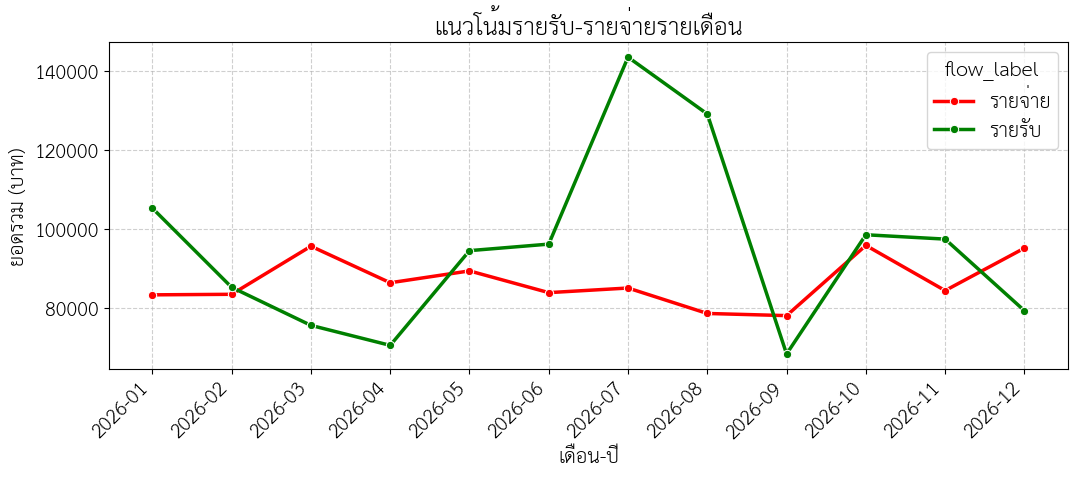

In [ ]:
print("กราฟแนวโน้มรายรับ-รายจ่ายรายเดือน")
trend_df = df.dropna(subset=['date_cleaned']).copy()
trend_df['year_month'] = trend_df['date_cleaned'].dt.to_period('M').astype(str)
trend_df['flow_label'] = trend_df['flow'].map({'income': 'รายรับ', 'expense': 'รายจ่าย'})
trend = trend_df.groupby(['year_month', 'flow_label'])['amount'].sum().reset_index()

plt.figure(figsize=(11, 5))
sns.lineplot(data=trend, x='year_month', y='amount', hue='flow_label',
             marker='o', linewidth=2.5, palette={'รายรับ': 'green', 'รายจ่าย': 'red'})
plt.title('แนวโน้มรายรับ-รายจ่ายรายเดือน')
plt.xlabel('เดือน-ปี'); plt.ylabel('ยอดรวม (บาท)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

กราฟรายรับ: รายเดือน และแยกตามแหล่งที่มา


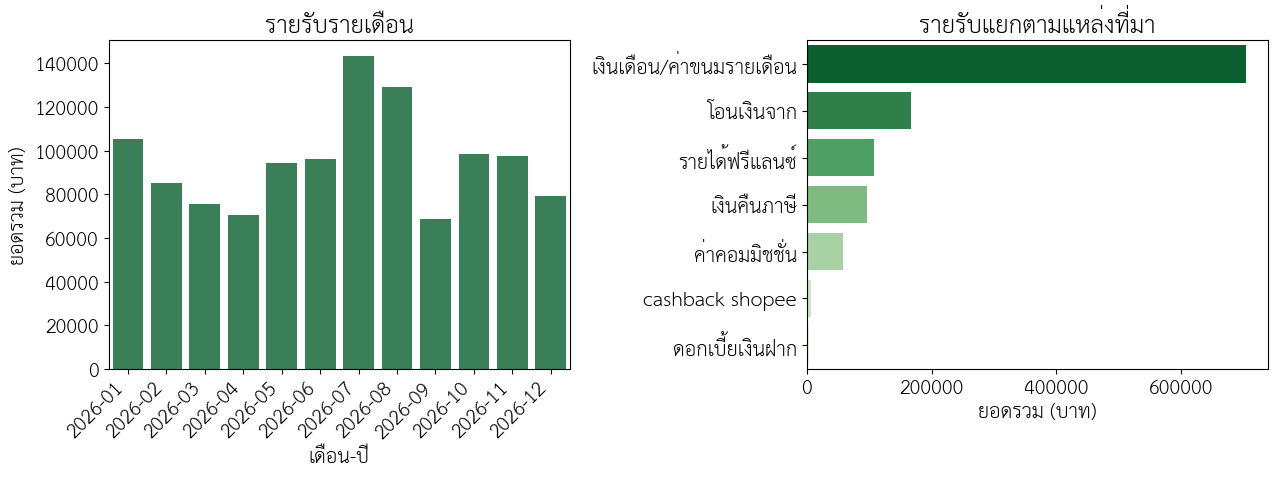

In [ ]:
print("กราฟรายรับ: รายเดือน และแยกตามแหล่งที่มา")
income_df = df[df['flow'] == 'income'].dropna(subset=['date_cleaned']).copy()
income_df['year_month'] = income_df['date_cleaned'].dt.to_period('M').astype(str)
monthly = income_df.groupby('year_month')['amount'].sum()
by_source = income_df.groupby('description_standard')['amount'].sum() \
                      .sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=monthly.index, y=monthly.values, color='seagreen', ax=axes[0])
axes[0].set_title('รายรับรายเดือน')
axes[0].set_xlabel('เดือน-ปี'); axes[0].set_ylabel('ยอดรวม (บาท)')
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')

sns.barplot(x=by_source.values, y=by_source.index,
            hue=by_source.index, palette='Greens_r', legend=False, ax=axes[1])
axes[1].set_title('รายรับแยกตามแหล่งที่มา')
axes[1].set_xlabel('ยอดรวม (บาท)'); axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

กราฟวงกลมแสดงสัดส่วนรายจ่ายแยกตามหมวดหมู่


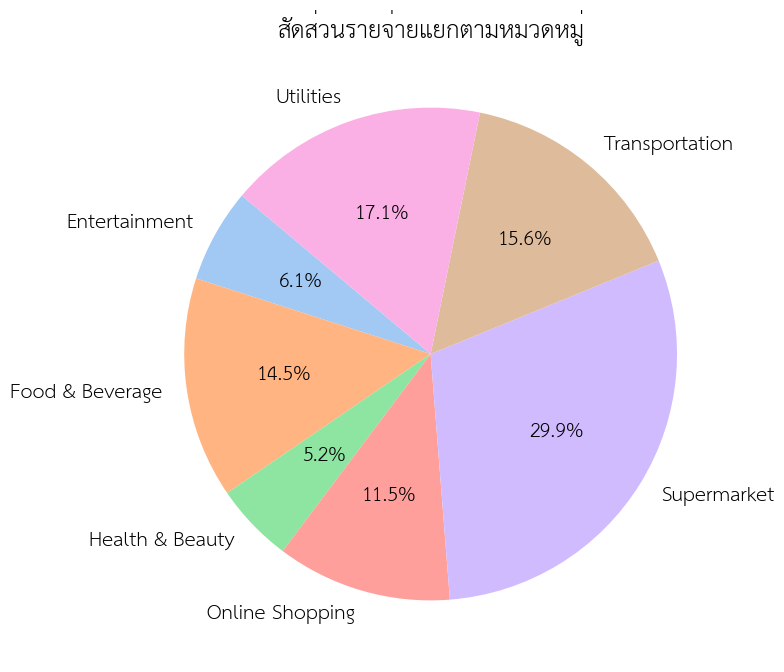

In [ ]:
print("กราฟวงกลมแสดงสัดส่วนรายจ่ายแยกตามหมวดหมู่")
expense_df = df[df['flow'] == 'expense']
category_summary = expense_df.groupby('category')['amount'].sum()

plt.figure(figsize=(8, 8))
plt.pie(category_summary.values, labels=category_summary.index,
        autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('สัดส่วนรายจ่ายแยกตามหมวดหมู่')
plt.show()

กราฟแสดง 10 อันดับร้านค้าที่จ่ายเงินบ่อยที่สุด (ไม่รวมรายรับ)


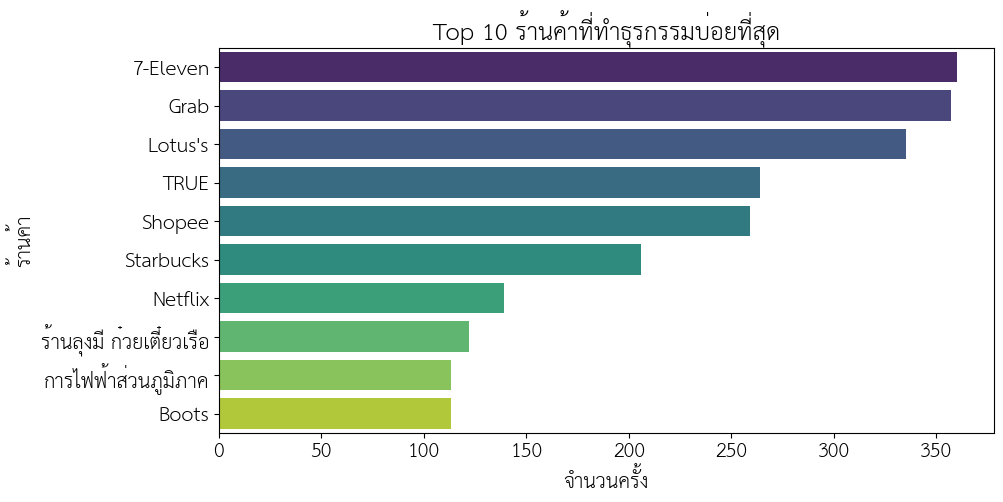

In [ ]:
print("กราฟแสดง 10 อันดับร้านค้าที่จ่ายเงินบ่อยที่สุด (ไม่รวมรายรับ)")
top_merchants = expense_df['description_standard'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_merchants.values, y=top_merchants.index,
            hue=top_merchants.index, palette='viridis', legend=False)
plt.title('Top 10 ร้านค้าที่ทำธุรกรรมบ่อยที่สุด')
plt.xlabel('จำนวนครั้ง'); plt.ylabel('ร้านค้า')
plt.show()

กราฟแสดง 10 อันดับร้านค้าที่ใช้เงินมากที่สุด (ไม่รวมรายรับ)


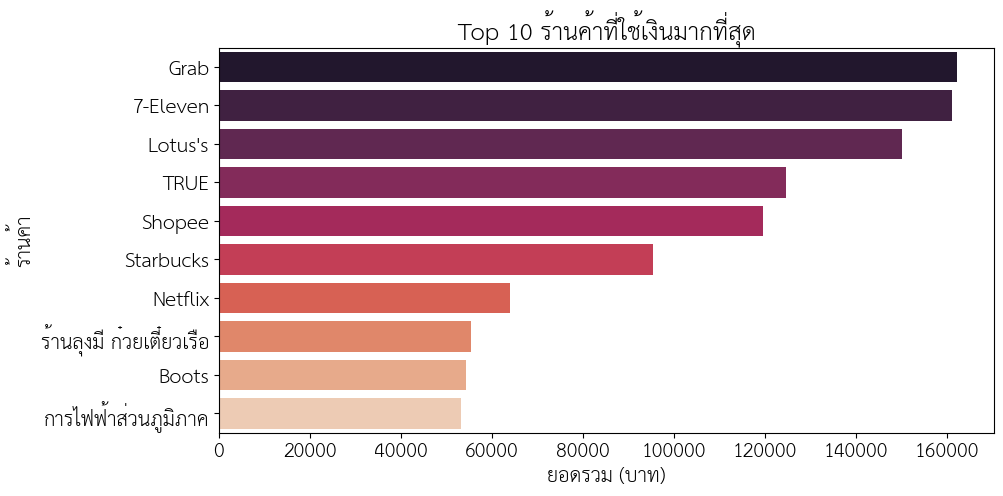

In [ ]:
print("กราฟแสดง 10 อันดับร้านค้าที่ใช้เงินมากที่สุด (ไม่รวมรายรับ)")
top_merchants_amount = expense_df.groupby('description_standard')['amount'].sum() \
                                  .sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_merchants_amount.values, y=top_merchants_amount.index,
            hue=top_merchants_amount.index, palette='rocket', legend=False)
plt.title('Top 10 ร้านค้าที่ใช้เงินมากที่สุด')
plt.xlabel('ยอดรวม (บาท)'); plt.ylabel('ร้านค้า')
plt.show()

กราฟสรุปปัญหาคุณภาพข้อมูลแยกตามประเภท


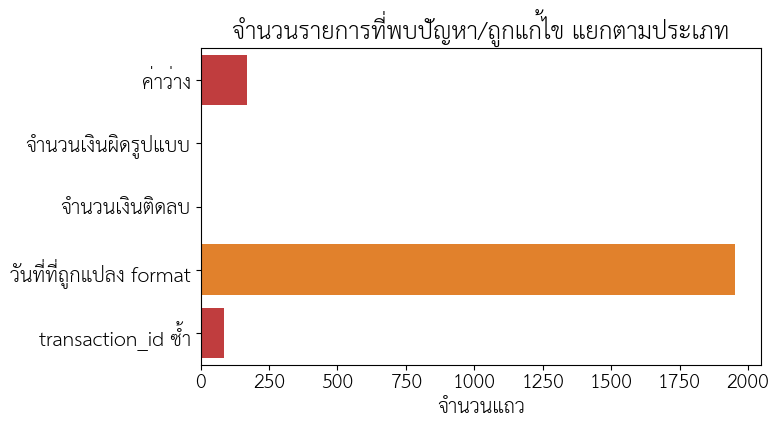

In [ ]:
print("กราฟสรุปปัญหาคุณภาพข้อมูลแยกตามประเภท")
labels = {
    'null_required': 'ค่าว่าง',
    'invalid_amount': 'จำนวนเงินผิดรูปแบบ',
    'negative_amount': 'จำนวนเงินติดลบ',
    'date_reformatted': 'วันที่ที่ถูกแปลง format',
    'duplicate_id': 'transaction_id ซ้ำ',
}

# ดึงค่าจากตัวแปรเดี่ยวที่มีอยู่จริงใน Kernel มาใส่ใน dictionary
report = {
    'null_required': null_required,
    'invalid_amount': invalid_amount,
    'negative_amount': negative_amount,
    'date_reformatted': date_reformatted,
    'duplicate_id': duplicate_id
}

vals = {labels[k]: report[k] for k in labels}

# สีแดง = ปัญหาจริง/ถูกตัดทิ้ง, สีส้ม = แก้ให้อัตโนมัติ (ไม่ใช่ปัญหา), สีเขียว = ไม่พบเลย
colors = []
for k, v in vals.items():
    if v == 0:
        colors.append('#2ca02c')
    elif k == 'วันที่ที่ถูกแปลง format':
        colors.append('#ff7f0e')
    else:
        colors.append('#d62728')

plt.figure(figsize=(8, 4.5))
sns.barplot(x=list(vals.values()), y=list(vals.keys()),
            hue=list(vals.keys()), palette=colors, legend=False)
plt.title('จำนวนรายการที่พบปัญหา/ถูกแก้ไข แยกตามประเภท')
plt.xlabel('จำนวนแถว')
plt.tight_layout()
plt.show()

In [ ]:
# คำนวณเปอร์เซ็นต์ข้อมูลที่ผ่านการตรวจสอบ
valid_percentage = (len(df) / total_raw) * 100 if total_raw > 0 else 0

# แสดงผลรายงานตามรูปแบบที่ต้องการ
print("ผลการตรวจสอบคุณภาพข้อมูล (Data Validation)")
print(f"o จำนวนแถวดิบทั้งหมด: {total_raw:,}")
print(f"o ผ่านการตรวจสอบและใช้งานได้: {len(df):,} แถว ({valid_percentage:.1f}%)")
print(f"o ค่าว่างในคอลัมน์จำเป็น: {null_required:,} แถว (ตัดออก)")
print(f"o จำนวนเงินไม่ใช่ตัวเลข: {invalid_amount:,} แถว (ตัดออก)")
print(f"o จำนวนเงินติดลบ: {negative_amount:,} แถว (ไม่นำมาคำนวณ แนะนำให้ตรวจสอบต้นฉบับ)")
print(f"o แปลง format วันที่ เป็น yyyy-mm-DD: {date_reformatted:,} แถว")
print(f"o transaction_id ซ้ำ: {duplicate_id:,} แถว (ตัดออก เก็บรายการแรกไว้)")

ผลการตรวจสอบคุณภาพข้อมูล (Data Validation)
o จำนวนแถวดิบทั้งหมด: 3,090
o ผ่านการตรวจสอบและใช้งานได้: 2,836 แถว (91.8%)
o ค่าว่างในคอลัมน์จำเป็น: 170 แถว (ตัดออก)
o จำนวนเงินไม่ใช่ตัวเลข: 0 แถว (ตัดออก)
o จำนวนเงินติดลบ: 0 แถว (ไม่นำมาคำนวณ แนะนำให้ตรวจสอบต้นฉบับ)
o แปลง format วันที่ เป็น yyyy-mm-DD: 1,951 แถว
o transaction_id ซ้ำ: 84 แถว (ตัดออก เก็บรายการแรกไว้)
